# Stage Conversion Accuracy

**Question:** for each pipeline stage, what share of deals that *ever* reached it ended up Closed Won, and how does that compare with the probability HubSpot assigns to the stage?

**Data:** `New_Client_Stage_History.csv` and `Existing_Client_Stage_History.csv`, pulled from the Element Three HubSpot portal on 2026-10-20 (New Business Pipeline and Existing Clients Pipeline; the Sextant pipelines are excluded, matching the original exports). Each row is a deal with its current stage and the date it entered each stage.

**Method:**
- A deal **reached** a stage if it has a `Date entered` for that stage *or any later stage*. That counts deals that skipped a stage as having passed it. Won deals count as reaching every stage.
- **Actual win %** = won ÷ reached, using closed deals only (Won, Lost, DQ).
- **Stated %** = the deal probability set on the stage in HubSpot.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.1f}'.format)

# Stage order and the probability configured on each stage in HubSpot
PIPELINES = {
    'New Client': {
        'file': 'New_Client_Stage_History.csv',
        'stages': {'Conversation': .10, 'Qualifying': .20, 'SME Step': .30, 'Approach': .50, 'SOW Sent': .90},
        'won': 'Closed Won', 'lost': ['Closed Lost', 'DQ'],
    },
    'Existing Client': {
        'file': 'Existing_Client_Stage_History.csv',
        'stages': {'5% Opportunity Identified': .05, '15% Opportunity Qualified': .15,
                   '30% Proposal in Development': .30, '50% Proposal Presented': .50,
                   '70% Verbal Commitment': .70, '90% SOW Submitted': .90},
        'won': '100% Closed Won', 'lost': ['Closed Lost'],
    },
}

def load(p):
    cfg = PIPELINES[p]
    d = pd.read_csv(cfg['file'])
    for c in ['Create Date', 'Close Date'] + [c for c in d.columns if c.startswith('Date entered')]:
        d[c] = pd.to_datetime(d[c], format='ISO8601', utc=True)
    d['Close Year'] = d['Close Date'].dt.year.astype('Int64')
    d['Amount'] = d['Amount'].fillna(0)
    d['Status'] = np.where(d['Deal Stage'] == cfg['won'], 'Won',
                  np.where(d['Deal Stage'].isin(cfg['lost']), 'Lost', 'Open'))
    return d

data = {p: load(p) for p in PIPELINES}
for p, d in data.items():
    print(p, d.shape, d['Status'].value_counts().to_dict())

New Client (926, 16) {'Lost': 718, 'Won': 184, 'Open': 24}
Existing Client (3011, 16) {'Won': 1867, 'Lost': 1053, 'Open': 91}


## 1. Is the stage history complete enough?

The share of closed deals with any stage date, and with a date for the first stage, by close year. Stage dates are reliable from about 2020. The first-stage column shows the process changed: New Client deals only started consistently entering at **Conversation** in 2023, and Existing Client deals at **5%** in 2024–25.

**So the main window is deals closed 2024–2026**, which reflects the current stage setup. Section 4 shows 2020–2026 for comparison.

In [2]:
cov = {}
for p, d in data.items():
    stages = list(PIPELINES[p]['stages'])
    closed = d[d['Status'] != 'Open']
    cov[p] = pd.DataFrame({
        'Closed deals': closed.groupby('Close Year').size(),
        'Any stage date %': closed.groupby('Close Year').apply(lambda x: x[['Date entered ' + s for s in stages]].notna().any(axis=1).mean() * 100),
        f'Entered {stages[0]} %': closed.groupby('Close Year')['Date entered ' + stages[0]].apply(lambda s: s.notna().mean() * 100),
    })
pd.concat(cov, axis=1).loc[2017:]

/var/folders/09/2rl5v52n3qx74l2pc1t00xvc0000gq/T/ipykernel_2261/1402518319.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'Any stage date %': closed.groupby('Close Year').apply(lambda x: x[['Date entered ' + s for s in stages]].notna().any(axis=1).mean() * 100),
/var/folders/09/2rl5v52n3qx74l2pc1t00xvc0000gq/T/ipykernel_2261/1402518319.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'Any stage date %': close

New Client                                          \
           Closed deals Any stage date % Entered Conversation %   
Close Year                                                        
2017                 68             44.1                    4.4   
2018                 98             87.8                   15.3   
2019                 90             95.6                   12.2   
2020                 65             98.5                    6.2   
2021                 58            100.0                    3.4   
2022                 59             93.2                    6.8   
2023                106             96.2                   90.6   
2024                 76            100.0                  100.0   
2025                 73            100.0                   97.3   
2026                101            100.0                   98.0   

           Existing Client                   \
              Closed deals Any stage date %   
Close Year                                    
2017                   NaN              NaN   
2018                   8.0             37.5   
2019                 411.0             65.5   
2020                 334.0             99.1   
2021                 381.0             91.9   
2022                 344.0             98.0   
2023                 388.0            100.0   
2024                 344.0            100.0   
2025                 382.0            100.0   
2026                 323.0            100.0   

                                                
           Entered 5% Opportunity Identified %  
Close Year                                      
2017                                       NaN  
2018                                       0.0  
2019                                      12.2  
2020                                      28.1  
2021                                      36.7  
2022                                      36.6  
2023                                      67.8  
2024                                      83.4  
2025                                      97.6  
2026                                      93.5

## 2. Ever-reached conversion by stage (deals closed 2024–2026)

In [3]:
def ever_reached(d, stages):
    """Closed deals only. Returns one row per stage: reached, won, actual vs stated win %."""
    closed = d[d['Status'] != 'Open']
    won = closed['Status'].eq('Won')
    entered = pd.DataFrame({s: closed['Date entered ' + s].notna() for s in stages})
    # Reached stage i if entered stage i or any later stage, or the deal was won
    reached = entered.iloc[:, ::-1].cummax(axis=1).iloc[:, ::-1].apply(lambda col: col | won)
    rows = []
    for s, prob in stages.items():
        r = reached[s]
        rows.append({'Stage': s, 'Reached': r.sum(), 'Won': (r & won).sum(),
                     'Stated %': prob * 100,
                     'Actual win %': (r & won).sum() / r.sum() * 100,
                     'Actual win % ($)': closed.loc[r & won, 'Amount'].sum() / closed.loc[r, 'Amount'].sum() * 100})
    t = pd.DataFrame(rows).set_index('Stage')
    t['Gap (pts)'] = t['Actual win %'] - t['Stated %']
    return t

WINDOW = (2024, 2026)
results = {}
for p, d in data.items():
    in_window = d[d['Close Year'].between(*WINDOW)]
    results[p] = ever_reached(in_window, PIPELINES[p]['stages'])
    print(f"\n{p}: closed {WINDOW[0]}-{WINDOW[1]}")
    display(results[p])


New Client: closed 2024-2026


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
Conversation,250,48,10.0,19.2,24.4,9.2
Qualifying,194,48,20.0,24.7,29.3,4.7
SME Step,139,48,30.0,34.5,37.5,4.5
Approach,97,48,50.0,49.5,49.4,-0.5
SOW Sent,51,48,90.0,94.1,95.2,4.1



Existing Client: closed 2024-2026


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
5% Opportunity Identified,1049,577,5.0,55.0,56.7,50.0
15% Opportunity Qualified,961,577,15.0,60.0,60.9,45.0
30% Proposal in Development,855,577,30.0,67.5,66.8,37.5
50% Proposal Presented,762,577,50.0,75.7,74.0,25.7
70% Verbal Commitment,649,577,70.0,88.9,87.2,18.9
90% SOW Submitted,622,577,90.0,92.8,91.9,2.8


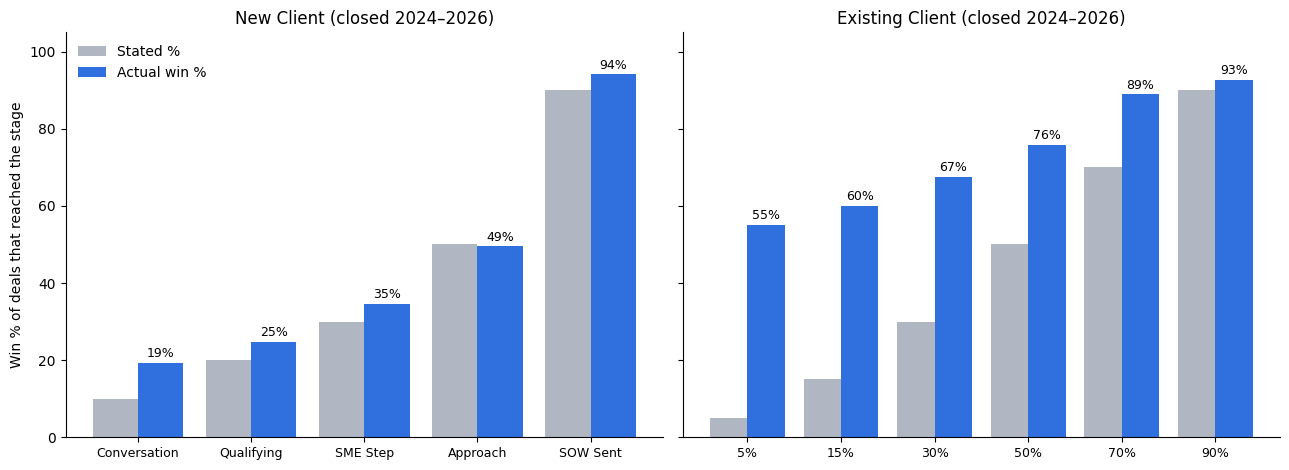

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (p, t) in zip(axes, results.items()):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['Stated %'], width=0.4, label='Stated %', color='#B0B7C3')
    ax.bar(x + 0.2, t['Actual win %'], width=0.4, label='Actual win %', color='#2F6FDE')
    for i, v in enumerate(t['Actual win %']):
        ax.text(i + 0.2, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([s.split(' ')[0] if p == 'Existing Client' else s for s in t.index], fontsize=9)
    ax.set_title(f'{p} (closed {WINDOW[0]}–{WINDOW[1]})')
    ax.set_ylim(0, 105)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Win % of deals that reached the stage')
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Sensitivity checks

- **New Client excluding DQ:** DQ deals were disqualified rather than lost competitively. Leaving them out shows conversion for qualified pipeline.
- **Existing Client excluding same-day deals:** some deals are created and marked won within a day, as paperwork for work already agreed. They click through every stage, so they inflate the early-stage rates.

In [5]:
new = data['New Client']
nw = new[new['Close Year'].between(*WINDOW) & (new['Deal Stage'] != 'DQ')]
print('New Client, excluding DQ')
display(ever_reached(nw, PIPELINES['New Client']['stages']))

ex = data['Existing Client']
ew = ex[ex['Close Year'].between(*WINDOW)]
same_day = (ew['Close Date'] - ew['Create Date']).dt.days <= 1
print(f"Existing Client, excluding {(same_day & (ew['Status'] != 'Open')).sum()} deals closed within a day of creation")
display(ever_reached(ew[~same_day], PIPELINES['Existing Client']['stages']))

New Client, excluding DQ


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
Conversation,154,48,10.0,31.2,34.9,21.2
Qualifying,138,48,20.0,34.8,36.4,14.8
SME Step,116,48,30.0,41.4,43.0,11.4
Approach,87,48,50.0,55.2,53.9,5.2
SOW Sent,50,48,90.0,96.0,97.3,6.0


Existing Client, excluding 71 deals closed within a day of creation


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
5% Opportunity Identified,978,514,5.0,52.6,56.0,47.6
15% Opportunity Qualified,892,514,15.0,57.6,60.2,42.6
30% Proposal in Development,788,514,30.0,65.2,66.1,35.2
50% Proposal Presented,697,514,50.0,73.7,73.4,23.7
70% Verbal Commitment,584,514,70.0,88.0,87.0,18.0
90% SOW Submitted,559,514,90.0,91.9,91.7,1.9


## 4. Longer history (deals closed 2020–2026)

In [6]:
for p, d in data.items():
    print(p)
    display(ever_reached(d[d['Close Year'].between(2020, 2026)], PIPELINES[p]['stages']))

New Client


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
Conversation,530,91,10.0,17.2,21.7,7.2
Qualifying,444,91,20.0,20.5,23.8,0.5
SME Step,331,91,30.0,27.5,29.8,-2.5
Approach,206,91,50.0,44.2,42.4,-5.8
SOW Sent,94,91,90.0,96.8,97.6,6.8


Existing Client


,Reached,Won,Stated %,Actual win %,Actual win % ($),Gap (pts)
Stage,,,,,,
5% Opportunity Identified,2496,1523,5.0,61.0,62.0,56.0
15% Opportunity Qualified,2375,1523,15.0,64.1,65.2,49.1
30% Proposal in Development,2151,1523,30.0,70.8,71.2,40.8
50% Proposal Presented,1958,1523,50.0,77.8,77.3,27.8
70% Verbal Commitment,1735,1523,70.0,87.8,87.6,17.8
90% SOW Submitted,1652,1523,90.0,92.2,92.7,2.2


## 5. Forecast impact on the open pipeline

Open deals weighted by the stated stage probability vs. by the actual 2024–2026 win rate for their current stage (dollar-based).

In [7]:
fc_all = []
for p, d in data.items():
    t = results[p]
    o = d[d['Status'] == 'Open']
    fc = o.groupby('Deal Stage').agg(Deals=('Amount', 'size'), Pipeline=('Amount', 'sum'))
    fc = fc.reindex([s for s in PIPELINES[p]['stages'] if s in fc.index])
    fc['Stated %'] = t.loc[fc.index, 'Stated %']
    fc['Actual %'] = t.loc[fc.index, 'Actual win % ($)']
    fc['Stated forecast'] = fc['Pipeline'] * fc['Stated %'] / 100
    fc['Actual-rate forecast'] = fc['Pipeline'] * fc['Actual %'] / 100
    fc.loc['Total'] = fc.sum(numeric_only=True)
    fc.loc['Total', ['Stated %', 'Actual %']] = np.nan
    fc.index = pd.MultiIndex.from_product([[p], fc.index])
    fc_all.append(fc)
pd.concat(fc_all).style.format({'Deals': '{:,.0f}', 'Pipeline': '${:,.0f}', 'Stated %': '{:.0f}%', 'Actual %': '{:.0f}%',
                                 'Stated forecast': '${:,.0f}', 'Actual-rate forecast': '${:,.0f}'}, na_rep='')

## Takeaways

**Existing Client pipeline: the stated probabilities are much too low through 50%.**
- Deals that reach 5% Opportunity Identified close **55%** of the time, not 5%. At 15% it's 60%, at 30% it's 68%, and at 50% it's 76%.
- Late stages are close: 70% Verbal Commitment converts at about **89%** and 90% SOW Submitted at about **93%**.
- Taking out same-day paperwork deals lowers the early stages by about 2 points. That doesn't change the conclusion.
- Effect: the open Existing pipeline is $5.45M. Stated probabilities forecast **$1.43M**; actual stage rates forecast about **$3.59M**.

**New Client pipeline: roughly accurate, slightly understated early.**
- Conversation **19%** vs. 10% stated, Qualifying **25%** vs. 20%, SME Step **35%** vs. 30%, Approach **50%** vs. 50%, SOW Sent **94%** vs. 90%.
- Excluding DQs, early stages run higher: Conversation about 31%, Qualifying about 35%.
- Over 2020–26 the middle stages run slightly *below* stated (SME Step 28%, Approach 44%), so these probabilities are close and the gaps are within normal year-to-year noise.
- Forecast: the open New pipeline is $2.18M. Stated probabilities forecast **$0.84M**; actual stage rates forecast about **$0.98M**.

**Suggested recalibration** (rounded 2024–26 actuals):

| Existing Client stage | Now | Suggested |
|---|---|---|
| 5% Opportunity Identified | 5% | 55% |
| 15% Opportunity Qualified | 15% | 60% |
| 30% Proposal in Development | 30% | 65% |
| 50% Proposal Presented | 50% | 75% |
| 70% Verbal Commitment | 70% | 90% |
| 90% SOW Submitted | 90% | 95% |

| New Client stage | Now | Suggested |
|---|---|---|
| Conversation | 10% | 20% |
| Qualifying | 20% | 25% |
| SME Step | 30% | 35% |
| Approach | 50% | 50% |
| SOW Sent | 90% | 95% |

**Caveats**
- HubSpot keeps one entry date per stage, so a deal that moved backward and forward is counted once per stage. That's fine for "ever reached."
- Some sample sizes are small, for example 51 New Client deals reached SOW Sent in 2024–26. Re-check yearly.